# s28nsc DGE, from saved labels only -- no training, no GPU

**What this answers.** The same niche-DGE comparison as
`notebooks/new_features/nassoc_density_d1_d2.ipynb`'s DGE section, on the same `s28nsc`
arms (`A_baseline`, `B_d1_pair`, the `C_d1d2_g*` sweep, `SEACells_bk08`) -- but this
notebook never constructs a model. Every arm already finished training and eval, so its
per-cell metacell labels are already saved to disk (`cell_assignments.csv` /
`umap_cells.csv`). `nd.labels_from_run` just reads that CSV -- it needs `pandas`, nothing
more -- so nothing here needs `torch`, `scarches`, the SEACells package, `faiss`, `cupy`,
or a GPU. Use this notebook when you want to re-slice/re-run the DGE metrics (new size
floors, a different reference arm, a new gamma once it's trained elsewhere) without paying
for the full training stack.

**If an arm you want isn't listed below** (e.g. a `C_d1d2_g*` value you haven't trained
yet), it has to be trained first in `nassoc_density_d1_d2.ipynb` -- this notebook is
read-only over what's already on disk.

**Dataset:** `s28nsc` only, K=200 (confirmed via `SEACells_bk08`'s own `metrics.json`:
`"K_target": 200`, matching every scProto arm's `NP200`).

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Deliberately NOT the training stack. `scanpy` pulls in numpy/scipy/pandas/anndata at
mutually-compatible versions on its own -- the multi-pass numpy/scipy pinning in the
training notebooks exists only to referee conflicts between scarches/SEACells/cupy, none
of which are installed here, so there's nothing to referee.

In [3]:
!pip install -q scanpy statsmodels diptest

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 30.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 238.1/238.1 kB 10.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 188.8/188.8 kB 7.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.0/40.0 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.9/10.9 MB 70.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.1/79.1 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.7/363.7 kB 15.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 60.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 69.4/69.4 kB 3.7 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==

**Restart the runtime now** (numpy/scipy/anndata are C-extension linked; an in-process
upgrade won't take effect on already-imported modules), then continue from the next cell.

In [4]:
_checks = {"numpy": "numpy", "scipy": "scipy", "anndata": "anndata", "scanpy": "scanpy",
           "statsmodels": "statsmodels", "diptest": "diptest"}
_failed = []
for pkg, mod in _checks.items():
    try:
        __import__(mod)
    except ImportError as e:
        _failed.append((pkg, str(e)))
if _failed:
    print("FAILED imports (fix before continuing, then restart runtime again):")
    for pkg, err in _failed:
        print(f"  {pkg}: {err}")
else:
    print("All packages import cleanly.")

All packages import cleanly.


In [5]:
%run /content/drive/MyDrive/codes/interpretable-prototype/notebooks/nb_setup.py

ModuleNotFoundError: No module named 'scib_metrics'

In [6]:
import os
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt

from interpretable_ssl.datasets.dataset_configs import DATASETS
from interpretable_ssl.evaluation import niche_dge as nd
from interpretable_ssl.evaluation.collapse_diagnostics import (
    metacell_sizes, dip_test, joint_purity_per_metacell, collapse_summary,
)

## Config

In [7]:
DS_ID = 's28nsc'
CT_KEY = 'celltypes'
NICHE_KEY = 'niches_2D'

# name -> keyword passed to nd.labels_from_run. Keywords are exact-enough substrings of the
# saved model folder names to be unambiguous (checked against the actual folder listing under
# MODEL_DIR/s28nsc/ -- e.g. 'ema15_ds-s28n' matches ONLY the baseline because B/C insert
# 'd1pair'/'d1d2_g...' between 'ema15' and 'ds-s28n' in their folder names).
ARMS = {
    # keywords are matched against extract_model_key's OUTPUT, which strips '_ds-<id>',
    # '_NP<k>', '_cvae_e<n>', '_v<n>' -- checked directly against the real folder names
    # (extract_model_key('proto_bk08_np200_ema15_ds-s28n_NP200_prtInit-wayp_...', ds_id='s28nsc')
    # -> 'proto_bk08_np200_ema15_prtInit-wayp_...'), so 'ds-s28n' must NOT appear in these.
    'A_baseline':    'ema15_prtInit',
    'B_d1_pair':     'ema15_d1pair',   # NOTE: no cell_assignments.csv/umap_cells.csv on disk for
                                       # this run yet (checkpoint + metrics.json only) -- will
                                       # SKIP until eval is (re-)run on it in Colab. See README.
    'C_d1d2_g0.01':  'd1d2_g0.01',
    'C_d1d2_g0.03':  'd1d2_g0.03',
    'C_d1d2_g0.1':   'd1d2_g0.1',
    'SEACells_bk08': 'seacell_bk08',
}
DGE_REFERENCE = 'B_d1_pair'

GT_PATH = os.path.join(os.environ['CODE_DIR'], 'files', 'celltype_niches_full_s28nsc.csv')
POOLED_PATH = os.path.join(os.environ['CODE_DIR'], 'files', 'celltype_pooled_de_s28nsc.csv')
NB_DIR = os.path.join(os.environ['CODE_DIR'], 'notebooks', 's28nsc_dge_lite')
TABLE_DIR = os.path.join(NB_DIR, 'tables')
FIG_DIR = os.path.join(NB_DIR, 'figures')
os.makedirs(TABLE_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)

FORCE_RERUN = False   # True only to deliberately recompute ground truth / per-arm DGE

## Load: adata (for obs labels + counts) and every arm's saved labels

No model is constructed anywhere below -- `labels_from_run` reads a CSV already written by
a previous training run.

In [8]:
ds_conf = DATASETS[DS_ID]
adata = sc.read_h5ad(ds_conf['path'])
print(adata)

AnnData object with n_obs × n_vars = 58423 × 960
    obs: 'section', 'celltypes', 'niches_3D', 'niches_2D', 'fibroblast_subclusters', 'tumor_pseudotime_rank', 'EMT_niche'
    uns: 'EMT_niche_colors', 'celltypes_colors', 'fibroblast_subclusters_colors', 'log1p', 'niches_2D_colors', 'niches_3D_colors', 'pca'
    obsm: 'X_covet', 'X_ctx', 'X_pca', 'X_umap_2D_neighbourhoods', 'X_umap_3D_neighbourhoods', 'X_umap_SCT', 'spatial'
    varm: 'PCs'
    layers: 'SCT', 'counts', None (.X)


In [9]:
labels = {}
for name, keyword in ARMS.items():
    lab = nd.labels_from_run(DS_ID, keyword, adata.obs_names)
    if lab is None or lab.isna().all():
        print(f'SKIP {name}: no saved cell assignments for keyword {keyword!r}')
        continue
    labels[name] = lab.dropna()
    print(f'{name}: {labels[name].nunique()} metacells over {len(labels[name])} cells '
          f'(keyword={keyword!r})')

print('\narms loaded:', list(labels))

SKIP A_baseline: no saved cell assignments for keyword 'ema15_ds-s28n'
SKIP B_d1_pair: no saved cell assignments for keyword 'ema15_d1pair'
C_d1d2_g0.01: 199 metacells over 58423 cells (keyword='d1d2_g0.01')
C_d1d2_g0.03: 177 metacells over 58423 cells (keyword='d1d2_g0.03')
C_d1d2_g0.1: 200 metacells over 58423 cells (keyword='d1d2_g0.1')
SEACells_bk08: 200 metacells over 58423 cells (keyword='seacell_bk08')

arms loaded: ['C_d1d2_g0.01', 'C_d1d2_g0.03', 'C_d1d2_g0.1', 'SEACells_bk08']


## Collapse shape (size / dip / purity only -- no affinity loaded, so no tightness columns,
same choice `spatial_new_loss_dge.ipynb` makes for the identical reason)

In [10]:
purity = {n: joint_purity_per_metacell(lab, adata, CT_KEY, NICHE_KEY) for n, lab in labels.items()}
collapse = pd.DataFrame([
    collapse_summary(lab, name=n, purity=purity[n]) for n, lab in labels.items()
]).set_index('run')
collapse['n_metacells'] = pd.Series({n: lab.nunique() for n, lab in labels.items()})
collapse['median_size'] = pd.Series({n: metacell_sizes(lab).median() for n, lab in labels.items()})
collapse.to_csv(os.path.join(TABLE_DIR, 'collapse_summary.csv'))
collapse.round(3)

,largest_share,dip_stat,dip_p,purity_micro,purity_gap,n_metacells,median_size
run,,,,,,,
C_d1d2_g0.01,0.168,0.106,0.000,0.314,0.138,199,5.0
C_d1d2_g0.03,0.164,0.107,0.000,0.307,0.242,177,5.0
C_d1d2_g0.1,0.159,0.085,0.000,0.313,0.152,200,5.0
SEACells_bk08,0.033,0.021,0.841,0.377,0.043,200,208.0


## Ground truth -- niche-vs-rest DE on real single cells (s28nsc-scoped path, computed once)

In [11]:
ground_truth = nd.get_ground_truth(adata, GT_PATH, ct_key=CT_KEY, niche_key=NICHE_KEY, force=FORCE_RERUN)
print(f'{len(ground_truth)} (cell type, niche) pairs')

ground truth: loaded from /content/drive/MyDrive/codes/interpretable-prototype/files/celltype_niches_full_s28nsc.csv  (146 (cell type, niche) pairs)
146 (cell type, niche) pairs


## DGE recovery per arm

In [12]:
results = {}
for name, lab in labels.items():
    results[name] = nd.run_niche_dge(
        name, lab, adata, ground_truth, TABLE_DIR,
        ct_key=CT_KEY, niche_key=NICHE_KEY, force=FORCE_RERUN,
    )

[C_d1d2_g0.01] computing — 199 metacells, median size 5 cells
[C_d1d2_g0.01] pseudobulk spot check corr(total counts, n_cells) = 0.720   (want ~1.0)


/usr/local/lib/python3.13/dist-packages/statsmodels/stats/weightstats.py:1011: RuntimeWarning: invalid value encountered in scalar divide
  z1 = (sem1 / semsum) ** 2 / (d1.nobs - 1)
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/weightstats.py:1012: RuntimeWarning: invalid value encountered in scalar divide
  z2 = (sem2 / semsum) ** 2 / (d2.nobs - 1)
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/weightstats.py:652: RuntimeWarning: invalid value encountered in scalar divide
  tstat = (value1 - value2 - diff) / std_diff


[C_d1d2_g0.01] computed and saved to /content/drive/MyDrive/codes/interpretable-prototype/notebooks/s28nsc_dge_lite/tables/C_d1d2_g0_01_per_pair.csv
[C_d1d2_g0.03] computing — 177 metacells, median size 5 cells
[C_d1d2_g0.03] pseudobulk spot check corr(total counts, n_cells) = 0.711   (want ~1.0)
[C_d1d2_g0.03] computed and saved to /content/drive/MyDrive/codes/interpretable-prototype/notebooks/s28nsc_dge_lite/tables/C_d1d2_g0_03_per_pair.csv
[C_d1d2_g0.1] computing — 200 metacells, median size 5 cells
[C_d1d2_g0.1] pseudobulk spot check corr(total counts, n_cells) = 0.698   (want ~1.0)
[C_d1d2_g0.1] computed and saved to /content/drive/MyDrive/codes/interpretable-prototype/notebooks/s28nsc_dge_lite/tables/C_d1d2_g0_1_per_pair.csv
[SEACells_bk08] computing — 200 metacells, median size 208 cells
[SEACells_bk08] pseudobulk spot check corr(total counts, n_cells) = 0.594   (want ~1.0)
[SEACells_bk08] computed and saved to /content/drive/MyDrive/codes/interpretable-prototype/notebooks/s28ns

In [13]:
summary = nd.summary_table(results)
summary.to_csv(os.path.join(TABLE_DIR, 'dge_summary.csv'))
summary.round(3)

,pearson_r,kendall_tau,pearson_r_std,kendall_tau_std,tpr,tpr_std,n_pairs,n_metacells,median_mc_size
C_d1d2_g0.01,0.202,0.193,0.082,0.081,0.727,0.193,26.0,199.0,5.0
C_d1d2_g0.03,0.253,0.143,0.298,0.253,0.767,0.137,19.0,177.0,5.0
C_d1d2_g0.1,0.240,0.175,0.117,0.075,0.676,0.132,19.0,200.0,5.0
SEACells_bk08,0.665,0.399,0.175,0.163,0.968,0.015,16.0,200.0,208.0


saved /content/drive/MyDrive/codes/interpretable-prototype/notebooks/s28nsc_dge_lite/figures/dge_summary.png


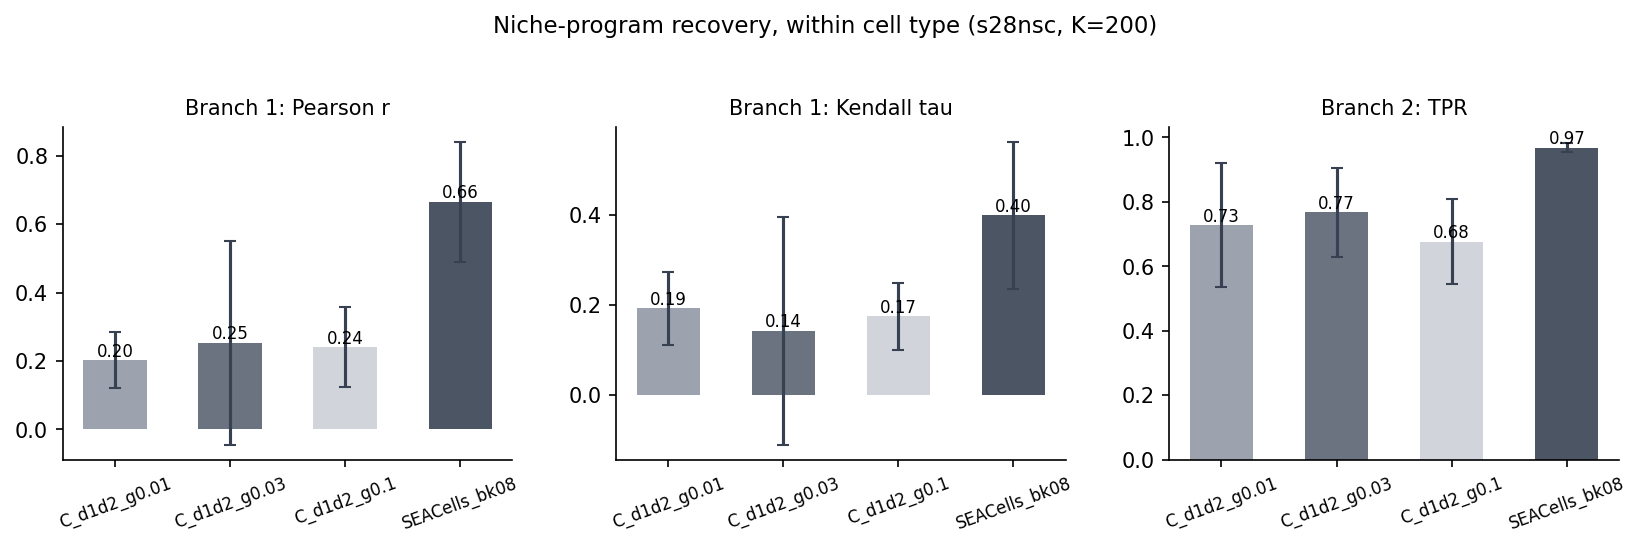

In [14]:
fig = nd.plot_dge_summary(
    summary, highlight=DGE_REFERENCE,
    out_path=os.path.join(FIG_DIR, 'dge_summary.png'),
    title='Niche-program recovery, within cell type (s28nsc, K=200)',
)
plt.show()

### Paired, per (cell type, niche)

In [15]:
paired = nd.compare_arms(results, reference=DGE_REFERENCE, metric='pearson_r')
gap_cols = [c for c in paired.columns if c.startswith('pearson_r_gap_')]
if gap_cols:
    paired = paired.sort_values(gap_cols[0], ascending=False)
paired.to_csv(os.path.join(TABLE_DIR, 'dge_paired.csv'), index=False)
paired.round(3).head(25)

KeyError: 'B_d1_pair'

### Size-floor sweep

In [ ]:
sweep = nd.size_floor_sweep(results, size_arm=DGE_REFERENCE)
sweep.to_csv(os.path.join(TABLE_DIR, 'dge_size_floor_sweep.csv'), index=False)
print(sweep.round(3).to_string(index=False))

In [ ]:
fig = nd.plot_size_floor_sweep(
    sweep, arms=list(results), highlight=DGE_REFERENCE,
    out_path=os.path.join(FIG_DIR, 'dge_size_floor_sweep.png'),
)
plt.show()